## Challenge 1: Predictions vs. Actual Results

### Circuit A — One X Gate
**Prediction:** The qubit will be measured as `1` in all 100 shots.

**Actual result:** 100 measurements of `1`.

**Conclusion:** The prediction was correct. The X gate flips the qubit from \(|0\rangle\) to \(|1\rangle\).

### Circuit B — Two X Gates
**Prediction:** The qubit will be measured as `0` in all 100 shots.

**Actual result:** 100 measurements of `0`.

**Conclusion:** The prediction was correct. Two successive X gates return the qubit to its initial state \(|0\rangle\).

### Circuit C — One H Gate
**Prediction:** Approximately 50 measurements of `0` and 50 measurements of `1`.

**Actual result:** 42 measurements of `0` and 58 measurements of `1`.

**Conclusion:** The result is consistent with the prediction. The Hadamard gate creates an equal superposition, so each outcome has a theoretical probability of 50%. Random variation in 100 measurements explains the difference in counts.


Circuit A - One X gate
Measurement results: {'1': 100}
Total shots: 100


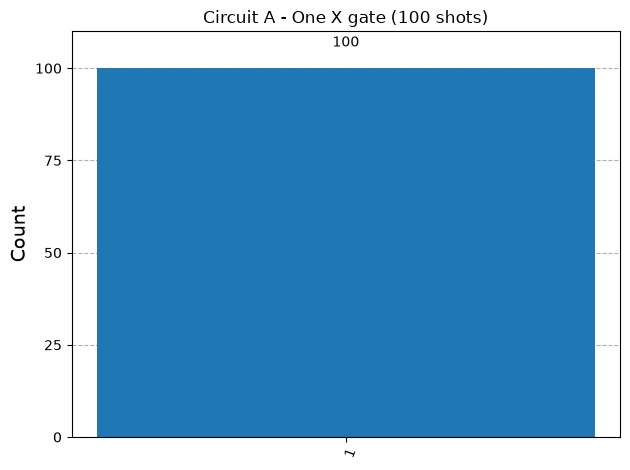


Circuit B - Two X gates
Measurement results: {'0': 100}
Total shots: 100


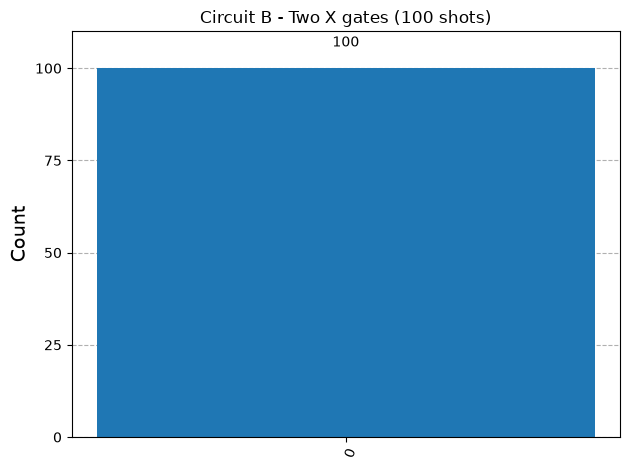


Circuit C - One H gate
Measurement results: {'0': 42, '1': 58}
Total shots: 100


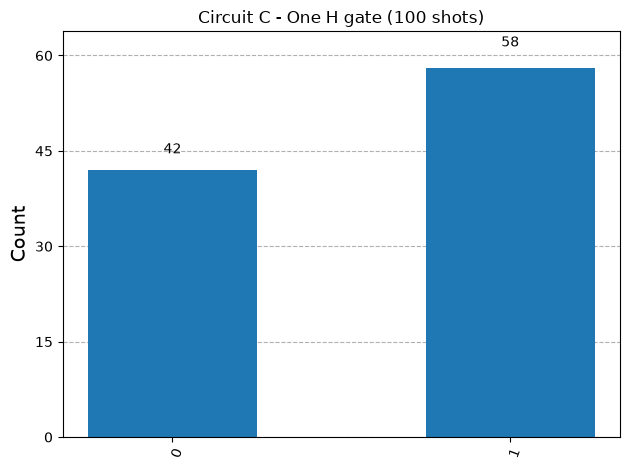

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

# Create the simulator
simulator = AerSimulator()

# Circuit A: One X gate
circuit_a = QuantumCircuit(1, 1)
circuit_a.x(0)
circuit_a.measure(0, 0)

# Circuit B: Two X gates
circuit_b = QuantumCircuit(1, 1)
circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

# Circuit C: One H gate
circuit_c = QuantumCircuit(1, 1)
circuit_c.h(0)
circuit_c.measure(0, 0)

# Store the circuits
circuits = {
    "Circuit A - One X gate": circuit_a,
    "Circuit B - Two X gates": circuit_b,
    "Circuit C - One H gate": circuit_c
}

# Run each circuit for 100 shots
results = {}

for name, circuit in circuits.items():
    result = simulator.run(circuit, shots=100).result()
    counts = result.get_counts()
    results[name] = counts

    print(f"\n{name}")
    print("Measurement results:", counts)
    print("Total shots:", sum(counts.values()))

    display(plot_histogram(
        counts,
        title=f"{name} (100 shots)"
    ))